In [14]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import airfrans as af
from scipy.stats import pearsonr, spearmanr
from afrans.config import (CACHE_DIR, CKPT_DIR, REPO_ROOT, DATA_ROOT,
                           TARGET_NAMES, POS, TARGETS, SURFACE, 
                           GridConfig, TrainConfig)
sys.path.append(str(REPO_ROOT / "scripts"))
from evaluate import load_full_sim, predict_sim   # reuse, don't re-derive

from afrans.graph_dataset import build_graph
from afrans.models.fno import build_fno
from afrans.models.gnn import build_gnn
from afrans.normalise import Normaliser
from afrans.splits import load_split, simulation_names
from afrans.metrics import relative_l2

### Load all results

In [2]:
fno_results = json.loads((REPO_ROOT / "results.json").read_text())
gnn_results = json.loads((REPO_ROOT / "results_gnn.json").read_text())

fno_ckpt_path = CKPT_DIR / (TrainConfig(loss_weighting="density").run_name(GridConfig()) + ".pt")
gnn_ckpt_path = CKPT_DIR / (TrainConfig(model="gnn").run_name() + ".pt")

fno_ck = torch.load(fno_ckpt_path, map_location="cpu", weights_only=False)
gnn_ck = torch.load(gnn_ckpt_path, map_location="cpu", weights_only=False)

fno_history = json.loads(fno_ckpt_path.with_suffix(".json").read_text())
gnn_history = json.loads(gnn_ckpt_path.with_suffix(".json").read_text())

print(f"FNO: {fno_ckpt_path.name}  best epoch {fno_ck['epoch']}  val_loss {fno_ck['val_loss']:.5f}  ({fno_results['n_sims']} val sims)")
print(f"GNN: {gnn_ckpt_path.name}  best epoch {gnn_ck['epoch']}  val_loss {gnn_ck['val_loss']:.5f}  ({gnn_results['n_val_sims']} val sims)")


FNO: fno_h32_m32x64_lr0.001_s42_density_128x256.pt  best epoch 46  val_loss 0.06920  (80 val sims)
GNN: gnn_h32_l4_k8_lr0.001_s42.pt  best epoch 46  val_loss 0.27363  (80 val sims)


### Training curves

Both FNO and GNN show healthy training curves. Noted the absolute loss value of these two model are not directly comparible, as the FNO was using a weighted loss where the surface grids have higher weight, whereas GNN was trained directly on the points, so the loss is not weighted.

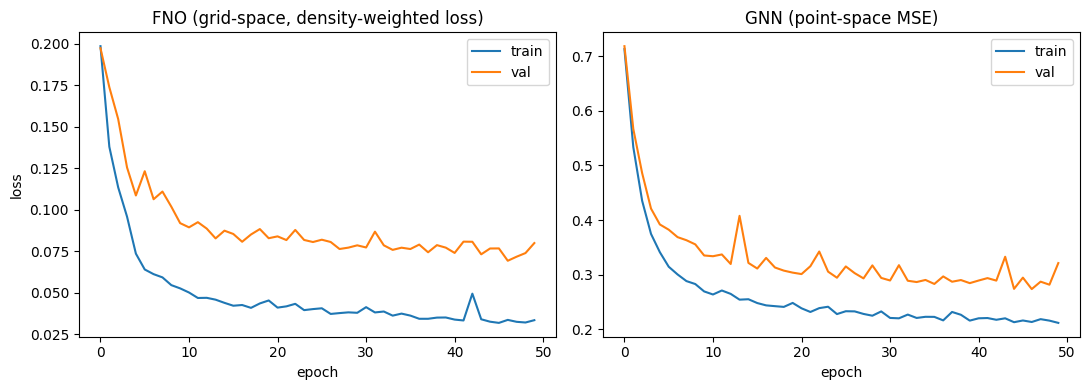

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fno_history["train"], label="train")
axes[0].plot(fno_history["val"], label="val")
axes[0].set_title("FNO (grid-space, density-weighted loss)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()

axes[1].plot(gnn_history["train"], label="train")
axes[1].plot(gnn_history["val"], label="val")
axes[1].set_title("GNN (point-space MSE)")
axes[1].set_xlabel("epoch"); axes[1].legend()

plt.tight_layout()
plt.show()


### Training time

FNO is much faster than GNN. Under this project's config, GNN's training time is nearly 10 times that of FNO.

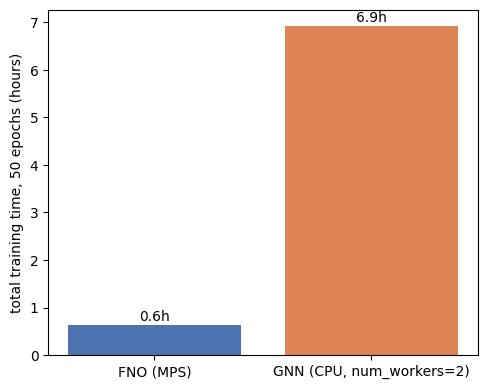

In [5]:
epoch_time_min = {"FNO (MPS)": 0.75, "GNN (CPU, num_workers=2)": 8.3}
total_time_hr = {k: v * 50 / 60 for k, v in epoch_time_min.items()}

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(total_time_hr.keys(), total_time_hr.values(), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("total training time, 50 epochs (hours)")
for i, (k, v) in enumerate(total_time_hr.items()):
    ax.text(i, v + 0.1, f"{v:.1f}h", ha="center")
plt.tight_layout()
plt.show()


### Relative L2 error

Compared with FNO, GNN has better results in all points, and especially in surface points. However, both models seem to struggle with pressure, the pressure predictions are heavy tailed. There are detailed investigations below.

In [11]:
names = ['vx','vy','pressure','nu_t']
for split in ['all_points','surface_points']:
    print(f'--- {split} ---')
    for n in names:
        f, g = fno_results[split][n], gnn_results[split][n]
        print(f"{n:10s} FNO {f['mean']:6.1%}±{f['std']:5.1%}   GNN {g['mean']:6.1%}±{g['std']:5.1%}")

--- all_points ---
vx         FNO  37.7%± 9.0%   GNN  22.4%± 6.5%
vy         FNO  63.0%±19.6%   GNN  38.2%±12.8%
pressure   FNO  85.2%±33.6%   GNN  58.8%±21.6%
nu_t       FNO  58.1%±12.6%   GNN  47.1%±12.4%
--- surface_points ---
vx         FNO 117.8%±38.4%   GNN  18.8%± 5.6%
vy         FNO  62.7%±46.8%   GNN  19.7%± 8.3%
pressure   FNO  86.7%±124.3%   GNN  60.7%±71.4%
nu_t       FNO  53.0%±22.3%   GNN  19.3%± 3.5%


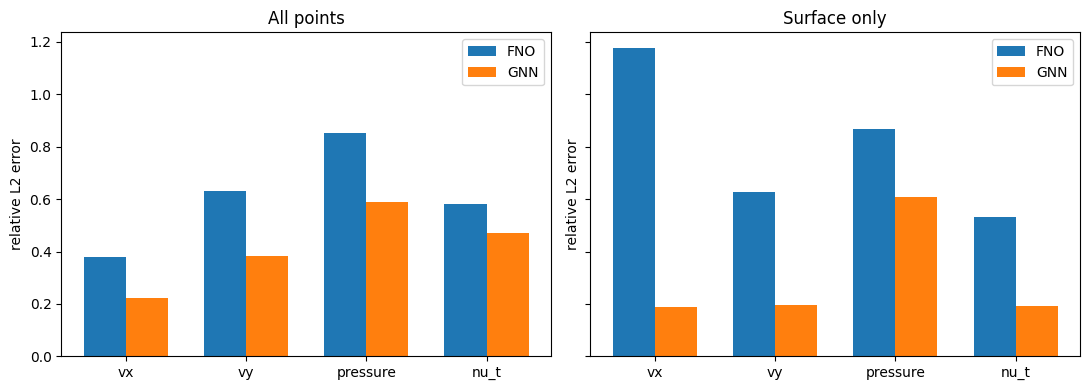

In [6]:
def to_means(results_dict, split):
    return [results_dict[split][name]["mean"] for name in TARGET_NAMES]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
x = np.arange(len(TARGET_NAMES))
width = 0.35

for ax, split, title in zip(axes, ["all_points", "surface_points"], ["All points", "Surface only"]):
    ax.bar(x - width/2, to_means(fno_results, split), width, label="FNO")
    ax.bar(x + width/2, to_means(gnn_results, split), width, label="GNN")
    ax.set_xticks(x); ax.set_xticklabels(TARGET_NAMES)
    ax.set_title(title)
    ax.set_ylabel("relative L2 error")
    ax.legend()

plt.tight_layout()
plt.show()


### Visualisation

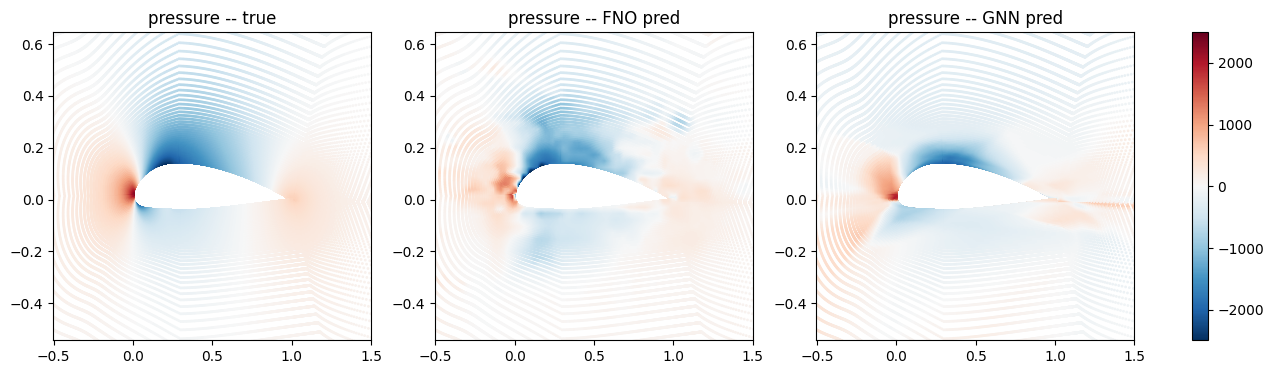

In [ ]:
norm = Normaliser(); norm.load(CACHE_DIR / "normaliser.npz")
val_names = load_split(names=simulation_names("full"))["val_names"]
name = val_names[0]
sim = load_full_sim(name)
pos = sim[:, POS]
y_true = sim[:, TARGETS]

fno_train_cfg = TrainConfig(**fno_ck["train_cfg"])
fno_grid_cfg = GridConfig(**fno_ck["grid_cfg"])
fno_model = build_fno(fno_train_cfg); fno_model.load_state_dict(fno_ck["model"]); fno_model.eval()
y_fno = predict_sim(fno_model, norm, fno_grid_cfg, torch.device("cpu"), sim)

gnn_train_cfg = TrainConfig(**gnn_ck["train_cfg"])
gnn_model = build_gnn(gnn_train_cfg); gnn_model.load_state_dict(gnn_ck["model"]); gnn_model.eval()
data = build_graph(name, norm, k=gnn_train_cfg.k_neighbors)
with torch.no_grad():
    y_gnn_norm = gnn_model(data.x, data.edge_index)
y_gnn = norm.inverse_target(y_gnn_norm.numpy())

channel = 2   # pressure
surf_pos = pos[sim[:, SURFACE] > 0.5]
pad = 0.5
x0, x1 = surf_pos[:, 0].min() - pad, surf_pos[:, 0].max() + pad
y0, y1 = surf_pos[:, 1].min() - pad, surf_pos[:, 1].max() + pad

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
vmax = np.abs(y_true[:, channel]).max()
for ax, vals, title in zip(axes, [y_true[:, channel], y_fno[:, channel], y_gnn[:, channel]],
                          ["true", "FNO pred", "GNN pred"]):
    sca = ax.scatter(pos[:, 0], pos[:, 1], c=vals, s=1, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_title(f"{TARGET_NAMES[channel]} -- {title}")
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
fig.colorbar(sca, ax=axes, fraction=0.02)
plt.show()


### Pressure investigation

To check if the large pressure std was a few outlier simulations, recomputed per simulation errors. The distribution is indeed heavy-tailed for both models (mean is roughly 2x the median), and 4 of the 5 worst simulations are the same for FNO and GNN. This suggests the difficulty comes from the simulation itself.

Also checked whether this correlates with angle of attack. Both models show a significant positive correlation between |AoA| and surface pressure error (GNN: Spearman ρ=0.78, p<0.0001; FNO: ρ=0.35, p=0.0016), consistent with near-stall flow conditions being intrinsically harder to predict, independent of model choice.

In [15]:
PRESSURE = 2  # index within TARGETS: vx, vy, pressure, nu_t

rows = []
for name in val_names:
    sim = load_full_sim(name)
    y_true = sim[:, TARGETS]
    surf = sim[:, SURFACE] > 0.5
    n_surf = surf.sum()

    y_fno = predict_sim(fno_model, norm, fno_grid_cfg, torch.device("cpu"), sim)
    fno_e = relative_l2(y_fno, y_true, mask=surf, ref_norm=norm.target_std * np.sqrt(n_surf))[PRESSURE]

    data = build_graph(name, norm, k=gnn_train_cfg.k_neighbors)
    with torch.no_grad():
        y_gnn_norm = gnn_model(data.x, data.edge_index)
    y_gnn = norm.inverse_target(y_gnn_norm.numpy())
    gnn_e = relative_l2(y_gnn, y_true, mask=data.surface.numpy(), ref_norm=norm.target_std * np.sqrt(n_surf))[PRESSURE]

    aoa_deg = np.degrees(af.Simulation(root=str(DATA_ROOT), name=name).angle_of_attack)
    rows.append({"name": name, "aoa_deg": aoa_deg,
                "fno_surf_pressure_err": fno_e, "gnn_surf_pressure_err": gnn_e})

df = pd.DataFrame(rows).sort_values("fno_surf_pressure_err", ascending=False).reset_index(drop=True)


The worst 10 simulations

In [16]:
df.head(10).style.format({
    "aoa_deg": "{:.1f}",
    "fno_surf_pressure_err": "{:.1%}",
    "gnn_surf_pressure_err": "{:.1%}",
})

,name,aoa_deg,fno_surf_pressure_err,gnn_surf_pressure_err
0,airFoil2D_SST_64.825_12.62_2.925_4.496_6.121,12.6,629.6%,430.0%
1,airFoil2D_SST_81.725_12.451_3.565_6.577_8.962,12.5,605.3%,322.4%
2,airFoil2D_SST_83.887_11.098_3.317_2.112_7.259,11.1,468.2%,270.4%
3,airFoil2D_SST_54.627_14.036_4.031_1.872_5.46,14.0,426.3%,278.6%
4,airFoil2D_SST_64.711_14.35_0.189_3.829_0.0_9.846,14.4,355.0%,126.0%
5,airFoil2D_SST_68.102_12.531_1.296_5.073_1.0_8.782,12.5,327.5%,151.0%
6,airFoil2D_SST_74.299_14.375_3.721_2.151_11.098,14.4,293.4%,62.7%
7,airFoil2D_SST_60.574_12.746_4.712_0.0_9.696,12.7,258.0%,97.1%
8,airFoil2D_SST_65.302_11.737_2.598_0.0_10.583,11.7,212.0%,62.0%
9,airFoil2D_SST_67.405_9.678_1.974_4.156_1.0_7.641,9.7,203.9%,102.9%


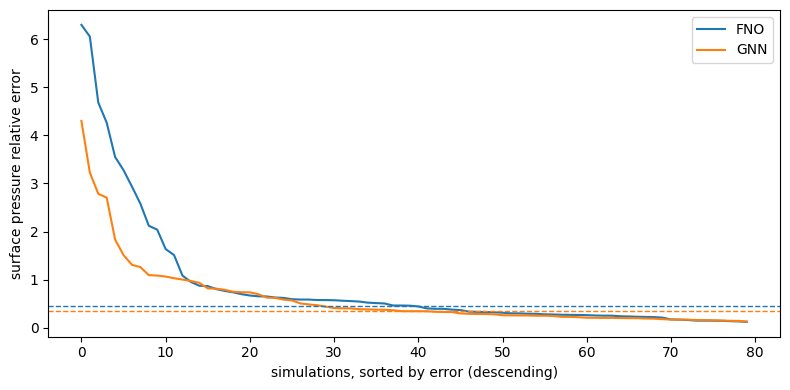

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sorted(df["fno_surf_pressure_err"], reverse=True), label="FNO")
ax.plot(sorted(df["gnn_surf_pressure_err"], reverse=True), label="GNN")
ax.axhline(df["fno_surf_pressure_err"].median(), color="C0", ls="--", lw=1)
ax.axhline(df["gnn_surf_pressure_err"].median(), color="C1", ls="--", lw=1)
ax.set_xlabel("simulations, sorted by error (descending)")
ax.set_ylabel("surface pressure relative error")
ax.legend()
plt.tight_layout()
plt.show()


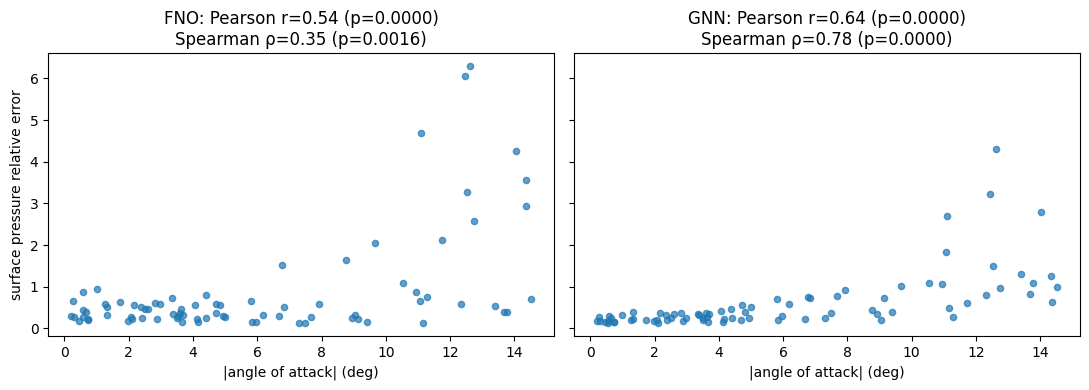

In [18]:
abs_aoa = df["aoa_deg"].abs()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, label in zip(axes, ["fno_surf_pressure_err", "gnn_surf_pressure_err"], ["FNO", "GNN"]):
    ax.scatter(abs_aoa, df[col], s=20, alpha=0.7)
    r, p = pearsonr(abs_aoa, df[col])
    rho, p_rho = spearmanr(abs_aoa, df[col])
    ax.set_title(f"{label}: Pearson r={r:.2f} (p={p:.4f})\nSpearman ρ={rho:.2f} (p={p_rho:.4f})")
    ax.set_xlabel("|angle of attack| (deg)")

axes[0].set_ylabel("surface pressure relative error")
plt.tight_layout()
plt.show()
